# Hate speech classification: Naive Bayes, Gradient Boosting, XGBoost, TabNet

Comparison of four supervised classifiers for labelling messages as hate speech or not, on a simplified, already preprocessed course dataset (`../data/out.csv`, not included in this repository).

Notebook text and comments are in Spanish. Pair project (UNIR, Machine Learning Techniques, MSc in Artificial Intelligence), February 2026.

Contents: EDA, model training, evaluation (accuracy, precision, recall, F1, ROC-AUC, cross-validation) and conclusions.


## EDA

In [78]:
# Se importan librerías
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

In [79]:
# se carga el dataset
df = pd.read_csv('../data/out.csv')
# Se muestran las primeras filas
print(df.shape)
display(df.head(3))
df.info()

(10000, 22)


,A,B,C,D,E,comentario,label,A_t,B_t,C_t,...,Valor_1,Valor_2,Valor_3,Valor_4,Valor_5,Valor_6,Valor_7,Valor_8,Valor_9,Valor_10
0,2,64,30,0,2,"pandemia,originado,covid,cierto,incidencia,aba...",0.0,1.851102,2.759647,7.145831,...,5.108388,13.227660,-0.771127,0.815665,19.719970,-1.149606,1.216004,-2.976790,3.148722,-0.183560
1,4,70,21,0,0,"ser,mes,larga,espera,llegar,momento,siempre,pr...",0.0,3.990202,3.054765,4.877255,...,12.189130,19.461233,-1.662227,-2.119191,14.898871,-1.272546,-1.622382,-2.031754,-2.590305,0.221244
2,4,88,50,0,0,"cartagena,san,sebastiar,fuengirola,irun,orense...",0.0,3.990202,3.940120,12.187108,...,15.721875,48.629021,-1.662227,-2.119191,48.018675,-1.641365,-2.092593,-5.076872,-6.472559,0.221244


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   A           10000 non-null  int64  
 1   B           10000 non-null  int64  
 2   C           10000 non-null  int64  
 3   D           10000 non-null  int64  
 4   E           10000 non-null  int64  
 5   comentario  10000 non-null  object 
 6   label       10000 non-null  float64
 7   A_t         10000 non-null  float64
 8   B_t         10000 non-null  float64
 9   C_t         10000 non-null  float64
 10  D_t         10000 non-null  float64
 11  E_t         10000 non-null  float64
 12  Valor_1     10000 non-null  float64
 13  Valor_2     10000 non-null  float64
 14  Valor_3     10000 non-null  float64
 15  Valor_4     10000 non-null  float64
 16  Valor_5     10000 non-null  float64
 17  Valor_6     10000 non-null  float64
 18  Valor_7     10000 non-null  float64
 19  Valor_8     10000 non-null

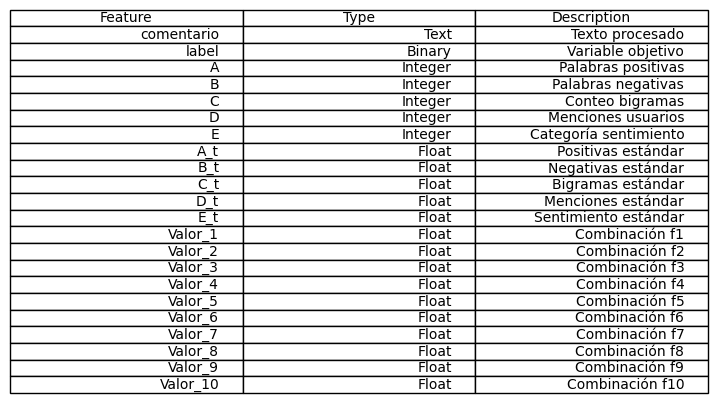

In [80]:
# De la descripción del dataset se plotean caracterísitcas y descripcioneS
data = [
    ("comentario", "Text", "Texto procesado"),
    ("label", "Binary", "Variable objetivo"),
    ("A", "Integer", "Palabras positivas"),
    ("B", "Integer", "Palabras negativas"),
    ("C", "Integer", "Conteo bigramas"),
    ("D", "Integer", "Menciones usuarios"),
    ("E", "Integer", "Categoría sentimiento"),
    ("A_t", "Float", "Positivas estándar"),
    ("B_t", "Float", "Negativas estándar"),
    ("C_t", "Float", "Bigramas estándar"),
    ("D_t", "Float", "Menciones estándar"),
    ("E_t", "Float", "Sentimiento estándar"),
    ("Valor_1", "Float", "Combinación f1"),
    ("Valor_2", "Float", "Combinación f2"),
    ("Valor_3", "Float", "Combinación f3"),
    ("Valor_4", "Float", "Combinación f4"),
    ("Valor_5", "Float", "Combinación f5"),
    ("Valor_6", "Float", "Combinación f6"),
    ("Valor_7", "Float", "Combinación f7"),
    ("Valor_8", "Float", "Combinación f8"),
    ("Valor_9", "Float", "Combinación f9"),
    ("Valor_10", "Float", "Combinación f10"),
]

plt.figure(figsize=(9, 4))
plt.axis("off")
plt.table(cellText=data, colLabels=["Feature", "Type", "Description"], loc="center")
plt.show()


*Nota: Valor 1-10 son combinaciones pares entre A,B,C,D,E = 10 posibles combinaciones*

In [81]:
# Aunque ya lo especifique en el enunciado, se haya no. de nulos y NaNs
print("Número de nulos por columna:")
print(df.isnull().sum().sort_values(ascending=False).head(3))
print("\nNúmero de NaNs por columna:")
print(df.isna().sum().sort_values(ascending=False).head(3))

#También se muestran datos estadísticos (desviacion, percentiles, media) de las variables numéricas
print("\nEstadística de las variables numéricas:")
print(df.describe())


Número de nulos por columna:
A    0
B    0
C    0
dtype: int64

Número de NaNs por columna:
A    0
B    0
C    0
dtype: int64

Estadística de las variables numéricas:
                  A             B             C             D             E  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.957400     26.098100      5.674600      0.091300      2.200600   
std        1.741864     34.012341      7.317149      0.352671      2.729488   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      1.000000      1.000000      0.000000      0.000000   
50%        0.000000      5.000000      3.000000      0.000000      0.000000   
75%        1.000000     46.000000      7.000000      0.000000      6.000000   
max       24.000000    328.000000     88.000000      6.000000      6.000000   

              label           A_t           B_t           C_t           D_t  \
count  10000.000000  10000.000000  10000.0

Como ya se detalla en el enunciado, el dataset ya ha sido preprocesado. Es por ello que al menos no existen valores nulos o faltantes en las variables, por lo que no es necesario imputar o limpiar adicionalmente. 

Sobre las distribuciones, se confirma que algunas variables (Valor1-10, continuas transformadas) sí están estandarizadas (media cercana a 0 y desviación cercana a 1), mientras que otras son variables discretas con valores enteros (A-E, conteos). No se observan valores extremos anómalos evidentes.

Más adelante se podría ver si las versiones transformadas y las nuevas combinaciones pudiesen "inyectar" información redundante a la hora de entrenar el modelo, aunque no es el objetivo en esta práctica. 

In [82]:
# Distribución de la variable objetivo
target_col = "label" 
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True).round(4))

# Cálculo de la tasa de acierto del baseline de la mayoría
maj_rate = df[target_col].value_counts(normalize=True).iloc[0] # La clase mayoritaria es la primera en el conteo
print("Majority baseline accuracy (precisión de clase mayoritaria):", round(maj_rate,4)) 

label
0.0    5000
1.0    5000
Name: count, dtype: int64
label
0.0    0.5
1.0    0.5
Name: proportion, dtype: float64
Majority baseline accuracy (precisión de clase mayoritaria): 0.5


La variable objetivo está perfectamente balanceada: 50% clase 0 y 50% clase 1.
Se evitará el problema del desbalance. Permite usar técnicas estándar sin tener que asignar más/menos peso a clases minoritarias. 

Majority baseline accuracy: precisión que se obtendría si siempre se predijese la clase mayoritaria. En este caso ambas clases están distribuídas de igual manera por lo que predecir siempre 1 o 0 conllevaría el 50% de aciertos. Por tanto, cualquier modelo debería estríctamente superar siempre este valor.

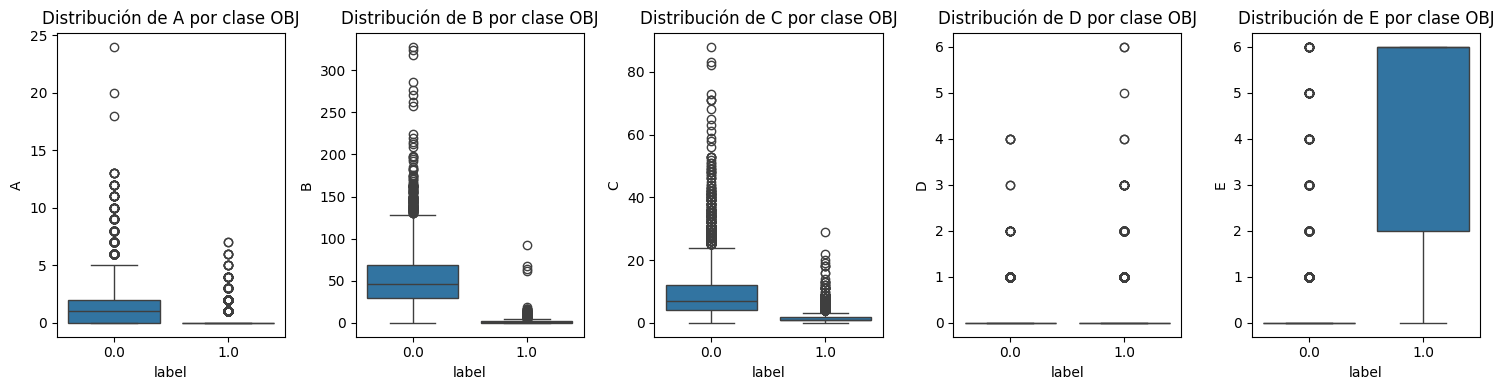

In [83]:
# Distribución de características numéricas por clase
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
featuresAE = ["A", "B", "C", "D", "E"]
featuresAE_t = ["A_t", "B_t", "C_t", "D_t", "E_t"]

for i, feature in enumerate(featuresAE):
    sns.boxplot(x="label", y=feature, data=df, ax=axes[i])
    axes[i].set_title(f"Distribución de {feature} por clase OBJ")

plt.tight_layout()
plt.show()

Las variables A B y C tienen claras diferencias entre clases monstrando más relevancia con la clase 0. La variable E muestra lo contrario, siendo más relevante en la clase 1. La variable D no presenta mucha discriminación. Puede que esto no sea tan consistente por la propia naturaleza de las variables (conteos palabras positivas, negativas, sentimiento, etc), aunque luego se comprobará. 

Text(0.5, 0.98, 'Distribuciones de las variables continuas estandarizadas')

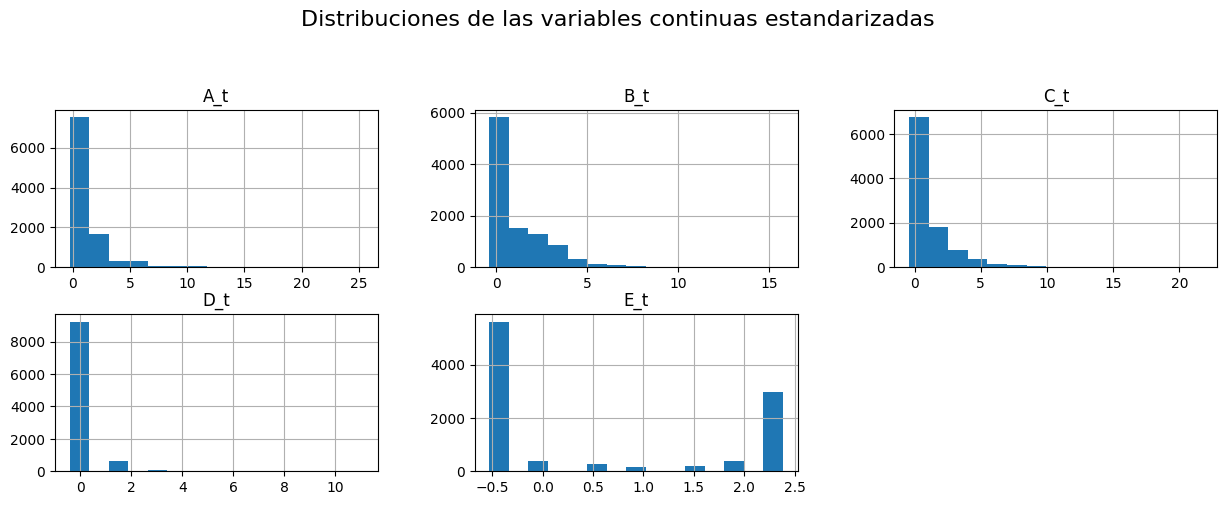

In [84]:
# Calculamos distribuciones de las variables estandarizadas
df[featuresAE_t].hist(bins=15, figsize=(15,10), layout=(4,3))
plt.suptitle("Distribuciones de las variables continuas estandarizadas", fontsize=16)  

Las variables estandarizadas no presentan simetría ni normalización. Algunas variables muestran fuerte concentración en rangos específicos lo que podría conllevar a sensibilidad por la escala. 

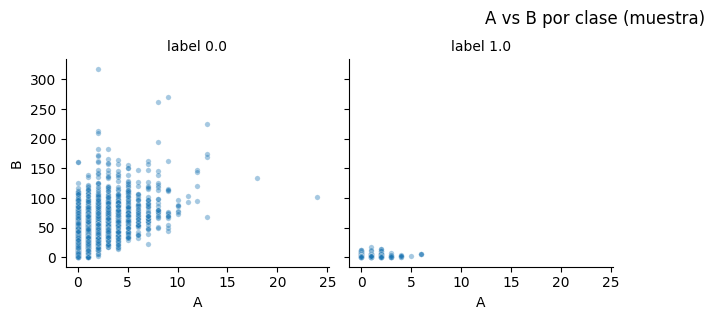

In [85]:
# Análisis bivariado: A vs B por clase (muestra)

df_plot = df.sample(n=5000, random_state=42)

g = sns.FacetGrid(
    df_plot,
    col='label',
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=True
)

g.map_dataframe(
    sns.scatterplot,
    x='A',
    y='B',
    alpha=0.4,
    s=15
)

g.set_titles('label {col_name}')
g.figure.suptitle('A vs B por clase (muestra)', y=1.05)
plt.show()

Se podría hacer con las demás variables para ver si hay estructuras diferenciadas entre las clases. En este caso, por ejemplo, el análisis bivariado muestra que la clase 1 se concentra en valores bajos de A y B, mientras que la clase 0 presenta mayor dispersión. 

In [86]:
# Cuánto aporta cada característica a la predicción de label
X_temp = df.drop(columns=["label", "comentario"])
y_temp = df["label"]

mi = mutual_info_classif(X_temp, y_temp)
mi_series = pd.Series(mi, index=X_temp.columns).sort_values(ascending=False)

mi_series.head(10)

Valor_7     0.602981
Valor_5     0.600356
Valor_6     0.577382
B           0.576194
B_t         0.574495
Valor_1     0.574392
Valor_9     0.498017
Valor_4     0.400223
Valor_10    0.370625
E_t         0.365103
dtype: float64

Se usa Mutual Information para evaluar la importancia de cada feature respecto a la variable objetivo, ya que permite detectar dependencias no lineales y podría ser adecuada para esta clasificación. En este análisis se indica que las variables transformadas (como Valor 5 y 7) sí presentan alta capacidad predictiva respecto a la variable objetivo. 

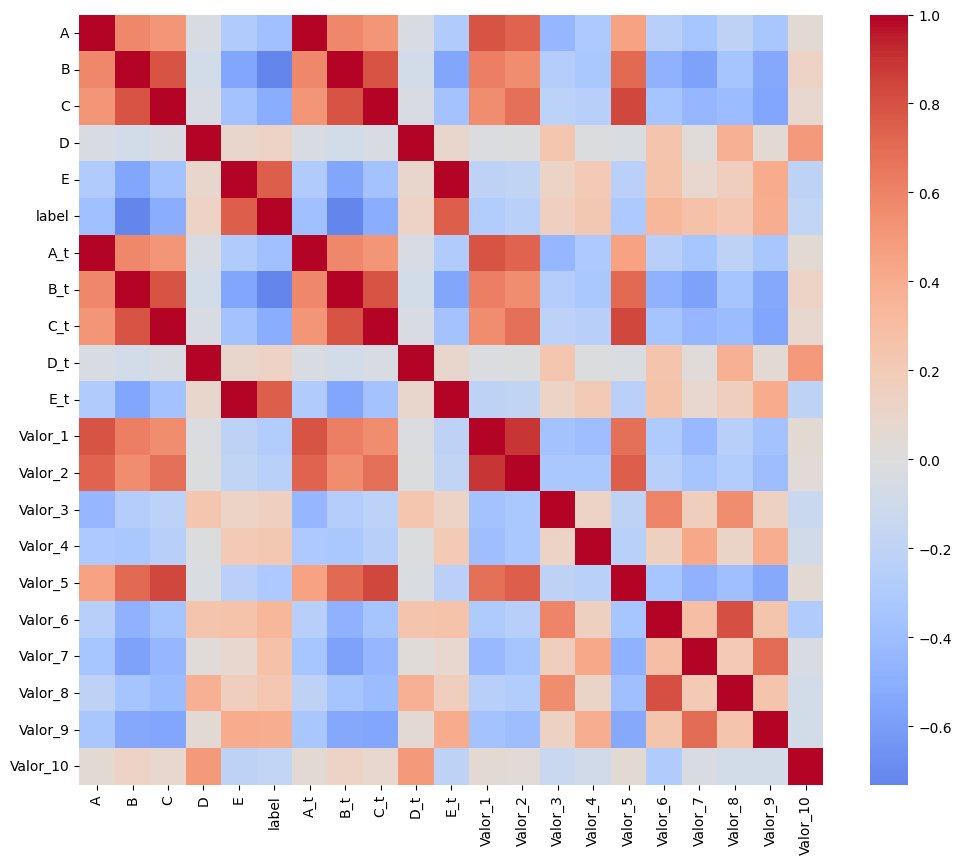

In [87]:
corr = df.drop(columns=["comentario"]).corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()

Muchas variables están correlacionadas con su transformada lo que indica redundancia fuerte. 

**CONCLUSIÓN DEL EDA:**
- Las clases de la variable objetivo están balanceadas
- Hay separibilidad entre varias variables
- Las variables transformadas (Valor_x) son muy informativas
- Hay redundancia considerable

## SELECCIÓN Y ENTRENAMIENTO DE LOS MODELOS

In [88]:
target_col = "label"
y = df[target_col]

### MULTINOMIAL NB 

Se usará esta variante de NB (otras serían GaussianNB o BernoulliNB). Este está pensada para conteos, frecuencias y datos BoW (los otros dos no encajan con las características del dataset). No es el modelo más óptimo pero sí el que más encaja acorde a lo estudiado en la última parte de la asignatura. MultinomialDB no puede manejar datos negativos por lo que habrá que estrictamente seleccionar columnas positivas. 

In [89]:
from sklearn.naive_bayes import MultinomialNB

In [90]:
# Solo variables no negativas. Se excluyen: comentario, variables transformadas y cualquier otra con valores negativos.

# Eliminamos columnas no numéricas
X_NB = df.drop(columns=["label", "comentario"])
# Eliminamos negativos
cols_non_negative = X_NB.columns[(X_NB.min() >= 0)]
X_NB = X_NB[cols_non_negative]

print("Columnas restantes:")
print(X_NB.columns)
print("\nX_NB:", X_NB.shape)
print("y:", y.shape)



Columnas restantes:
Index(['A', 'B', 'C', 'D', 'E'], dtype='object')

X_NB: (10000, 5)
y: (10000,)


Es cierto que muchas de las columnas estandarizadas y procesadas no se tendrán en consideración y quizá este modelo no ofreza los resultados más óptimos, pero se usará como primero para evaluar métricas, investigar sobre NB y comparar con los siguientes

In [91]:
# Estratificado para mantener proporcion de clases en train y test
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(
    X_NB,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [92]:
# Se entrena modelo con parámetros por defecto 
model_nb = MultinomialNB(
    alpha=1.0,              # alpha = 1.0 = suavizado de Laplace estándar, evita probabilidades 0
    fit_prior=True,         # aprende las probabilidades a priori de las clases a partir de los datos
    class_prior=None)       # probabilidades a priori de las clases iguales (si None, se aprenden de los datos)

# Entrenamiento
model_nb.fit(X_train_nb, y_train_nb)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [93]:
# Predicciones test
y_pred_nb = model_nb.predict(X_test_nb)
# Probabilidades de clase para test para métricas como ROC AUC
y_prob_nb = model_nb.predict_proba(X_test_nb)

# EN LA SIGUIENTE SECCIÓN SE EVALÚAN LOS RESULTADOS

## GRADIENT BOOSTING (BOOSTING SECUENCIAL)

Se entrenarán árboles uno detrás de otro, donde cada árbol corregirá el error del anterior. Para ello se una función de pérdida usando gradiente descendente. A diferencia de bagging, este método es secuencial y no paralelo. Este buscará minimizar el error "acumulado" y no reducir varianzas o promediar resultados como pasa con bagging (Random forest por ejemplo).

Este método se ha investigado más en detenimiento a partir de las siguientes fuentes:
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- https://www.digitalocean.com/community/tutorials/gradient-boosting-for-classification (teóricamente el más copleto)
- https://machinelearningmastery.com/gradient-boosting-with-scikit-learn-xgboost-lightgbm-and-catboost/ (usan versiones y modelos optimizados de Gradient Boosting como XGBoost, LightGBM o CatBoost que quizá se prueben en este ejercicio para comparar resultados)
- Chatgpt / CUrsor: para depurar y corregir errores de código, y para depurar conceptos teóricos. 



In [94]:
from sklearn.ensemble import GradientBoostingClassifier

In [95]:
# Se vuelve a separar train y tests split por si acaso.

# Eliminamos variables no numéricas. No hace falta eliminar negativas porque el modelo de Gradient Boosting puede manejarlas.
X_GB = df.drop(columns=["label", "comentario"])

# Comprobación
print("Columnas restantes:")
print(X_GB.columns)
print("\nX_GB:", X_GB.shape)
print("y:", y.shape)

# Split manteniendo proporción de clases
X_train_GB, X_test_GB, y_train_GB, y_test_GB = train_test_split(
    X_GB,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Columnas restantes:
Index(['A', 'B', 'C', 'D', 'E', 'A_t', 'B_t', 'C_t', 'D_t', 'E_t', 'Valor_1',
       'Valor_2', 'Valor_3', 'Valor_4', 'Valor_5', 'Valor_6', 'Valor_7',
       'Valor_8', 'Valor_9', 'Valor_10'],
      dtype='object')

X_GB: (10000, 20)
y: (10000,)


In [96]:
# Parámetros iniciales (se irá probando)
model_gb = GradientBoostingClassifier(
    n_estimators=100,      # número de árboles
    learning_rate=0.1,     # peso de cada árbol
    max_depth=3,           # profundidad de cada árbol
    subsample=1.0,        # muestreo de filas (1 todo el dataset)
    max_features=None,    # uso de todas las características para cada árbol
    criterion='friedman_mse', # criterio de división (predeterminado para clasificación)
    min_samples_split=2,  # número mínimo de muestras para dividir un nodo
    min_samples_leaf=1,   # número mínimo de muestras en una hoja
    min_impurity_decrease=0.0, # umbral de impureza para dividir nodos
    tol=0.0001,            # tolerancia para la detención temprana
    random_state=42 
)

# Entrenamiento
model_gb.fit(X_train_GB, y_train_GB)

,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are'friedman_mse' for the mean squared error with improvement score byFriedman, 'squared_error' for mean squared error. The default value of'friedman_mse' is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, 

In [97]:
# Se obtienen predicciones
y_pred_GB = model_gb.predict(X_test_GB)
# Probabilidades de clase en test para métricas como ROC AUC
# Receiver Operating Characteristic (area bajo la curva) teniendo en cuenta positivos reales 
y_prob_gb = model_gb.predict_proba(X_test_GB)[:,1]


### XGBOOST

Como extra sin meternos en la base matemática

In [98]:
# Probamos XGBoost (GB optimizado) por curiosidad
# pip install xgboost
import xgboost as xgb
from xgboost import XGBClassifier


In [99]:

# Boosting optimizado. Se han probado varios valores para los hiperparámetros. Se podría haber hecho RandomizedSearchCV o GridSearchCV.
model_xgb = XGBClassifier(
    n_estimators=200,      # número de árboles
    learning_rate=0.05,    # peso de cada árbol
    max_depth=4,           # profundidad de cada árbol
    subsample=0.8,         # muestreo filas (80% del dataset para cada árbol)
    colsample_bytree=0.8,  # muestreo columnas
    eval_metric="logloss", # métrica de evaluación
    random_state=42,
    use_label_encoder=False # parece que es para evitar warnings o errores en ejecución con versiones de XGBoost recientes
)

# Entrenamiento
model_xgb.fit(X_train_GB, y_train_GB)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_metho

In [100]:
# Predicciones
y_pred_xgb = model_xgb.predict(X_test_GB)
y_prob_xgb = model_xgb.predict_proba(X_test_GB)[:,1]

### TABNET (Experimental, de Google)

In [101]:
#pip install pytorch-tabnet torch

TabNet (De Google) es una especia de arquitectura de deep learning para datos tabulares que usa una forma secuencial para seleccionar qué variables usar en cada “paso de decisión”, buscando combinar lo mejor de árbole con lo mejor de redes. Se ha usado este modelo de forma experimental para investigar más a fondo otras alternativas estudiadas en el temario:

- Arik, S. O., & Pfister, T. (2019). TabNet: Attentive Interpretable Tabular Learning. arXiv:1908.07442.
- https://medium.com/@kdk199604/tabnet-a-deep-learning-breakthrough-for-tabular-data-bcd39c47a81c
- https://research.google/pubs/tabnet-attentive-interpretable-tabular-learning/ 
- Otras fuentes semejantes.
- IAs generativas (Chatgpt)

In [102]:
import torch
from pytorch_tabnet.tab_model import TabNetClassifier

In [103]:
# X será el mismo que para GB, ya que TabNet también puede manejar variables negativas y no numéricas
X_tab = df.drop(columns=["label", "comentario"]).to_numpy(dtype=np.float32)

# y seguirá siendo label 
y_tab = df["label"].to_numpy(dtype=int)

In [104]:
# Para no interferir, se generar nuevos splits  
X_train_TN, X_test_TN, y_train_TN, y_test_TN = train_test_split(
    X_tab, y_tab, test_size=0.2, random_state=42, stratify=y_tab
)

# Parámetros iniciales (se irá probando) de TabNet.
model_tabnet = TabNetClassifier(
    n_d=16, n_a=16, n_steps=5,          # decisión, atention y número de pasos
    optimizer_fn=torch.optim.Adam,      # más o menos estándar para TabNet
    optimizer_params=dict(lr=2e-2),     # sensible al learning rate, se han probado varios valores 
    mask_type="entmax",                 # suele ir bien en tabular
    seed=42                             # aleatoriedad  
)

# Entrenamiento
model_tabnet.fit(
    X_train_TN, y_train_TN,
    eval_set=[(X_test_TN, y_test_TN)],
    eval_metric=["auc"],    # metrica de evaluación - se irá probando   
    max_epochs=100,         # número máximo de épocas / early stopping
    patience=15,            # número de épocas sin mejora para detener el entrenamiento
    batch_size=1024,        # lote
    virtual_batch_size=128, #parámetro predefinido, se investigará su relacion
    drop_last=False         # para no descartar datos si el número de muestras no es divisible por el batch size
)

epoch 0  | loss: 0.54785 | val_0_auc: 0.94011 |  0:00:01s
epoch 1  | loss: 0.21184 | val_0_auc: 0.97797 |  0:00:02s
epoch 2  | loss: 0.14744 | val_0_auc: 0.98297 |  0:00:04s
epoch 3  | loss: 0.13612 | val_0_auc: 0.9865  |  0:00:05s
epoch 4  | loss: 0.12235 | val_0_auc: 0.99042 |  0:00:06s
epoch 5  | loss: 0.10982 | val_0_auc: 0.99091 |  0:00:07s
epoch 6  | loss: 0.0986  | val_0_auc: 0.98994 |  0:00:09s
epoch 7  | loss: 0.09296 | val_0_auc: 0.9909  |  0:00:10s
epoch 8  | loss: 0.09061 | val_0_auc: 0.9911  |  0:00:12s
epoch 9  | loss: 0.09718 | val_0_auc: 0.99097 |  0:00:13s
epoch 10 | loss: 0.08998 | val_0_auc: 0.99239 |  0:00:14s
epoch 11 | loss: 0.086   | val_0_auc: 0.99281 |  0:00:15s
epoch 12 | loss: 0.09208 | val_0_auc: 0.99375 |  0:00:17s
epoch 13 | loss: 0.08435 | val_0_auc: 0.99452 |  0:00:18s
epoch 14 | loss: 0.0804  | val_0_auc: 0.99441 |  0:00:19s
epoch 15 | loss: 0.07546 | val_0_auc: 0.99519 |  0:00:20s
epoch 16 | loss: 0.07532 | val_0_auc: 0.9952  |  0:00:22s
epoch 17 | los

## EVALUACIÓN DE LOS MODELOS Y COMPARATIVA

In [105]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

### MULTINOMIAL NB 

Accuracy: 0.942
F1 Score: 0.9391
Precision: 0.9879
Recall: 0.895

Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.99      0.94      1000
         1.0       0.99      0.90      0.94      1000

    accuracy                           0.94      2000
   macro avg       0.95      0.94      0.94      2000
weighted avg       0.95      0.94      0.94      2000



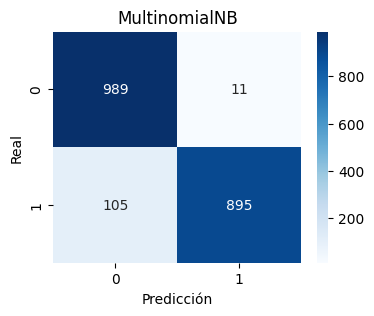

In [106]:
# Precisión y otras métricas
acc_NB = accuracy_score(y_test_nb, y_pred_nb)
f1_NB = f1_score(y_test_nb, y_pred_nb)
precision_NB = precision_score(y_test_nb, y_pred_nb)
recall_NB = recall_score(y_test_nb, y_pred_nb)
print("Accuracy:", round(acc_NB, 4))
print("F1 Score:", round(f1_NB, 4))
print("Precision:", round(precision_NB, 4))
print("Recall:", round(recall_NB, 4))

print("\nClassification Report:")
print(classification_report(y_test_nb, y_pred_nb))

# Matriz de confusión
cm_NB = confusion_matrix(y_test_nb, y_pred_nb)

plt.figure(figsize=(4,3))
sns.heatmap(cm_NB, annot=True, fmt="d", cmap="Blues")
plt.title("MultinomialNB")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()



Se han obtenido distintas métricas para el modelo MultinomialDB sobre el conjunto de test:
- Se alcanza un accuracy del 94% superando considerablemente el baseline (antes mencionado) del 50%.
- Ambas clases (1 y 0) presentan métricas equilibradas lo que indica que el modelo no está sesgado hacia una clase concreta.
- La matriz de confusión muestra que los errores se concentran principalmente en falsos negativos de la clase 1.
- El F1 medio (combinación acc-recall) es considerablemente alto (0.94) para ambas clases. 

In [107]:
# Se prueba con validación cruzada para confirmar estabilidad de resultados anteriores.
cross_val_NB = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # Se obtienen 5 folds proporcionales

scores = cross_val_score(
    model_nb,
    X_NB,
    y,
    cv=cross_val_NB,
    scoring="f1"
)

print("F1 por fold:", scores)
print("F1 medio:", scores.mean())
print("STD:", scores.std())

F1 por fold: [0.93291072 0.93565401 0.9309436  0.93713682 0.9434555 ]
F1 medio: 0.9360201289105742
STD: 0.004291977233317349


Para comprobar la estabilidad del modelo se ha aplicado validación cruzada con 5 folds.
- El F1 medio obtenido es aproximadamente 0.936 con una desviación estándar muy baja (apenas 0.004)

Esto indica que el modelo es estable y robusto ante las diferentes particiones. En general el modelo ha presentado resultados muy positivos a partir de únicamente las variables A-E, aunque es algo de esperar ya que estas columnas no son mediciones o sensores, sino que provienen de conteos y análisis previos. El dataset ya cotiene información semántica resumida después de haber aplicado técnicas de PLN previamente. 

In [108]:
# PODRIAMOS METER ROC AUC a partir de las probabilidades de clase (y_prob) 


## GRADIENT BOOSTING

Accuracy: 0.981
F1 Score: 0.981
Precision: 0.981
Recall: 0.981

Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98      1000
         1.0       0.98      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000


ROC-AUC: 0.9973


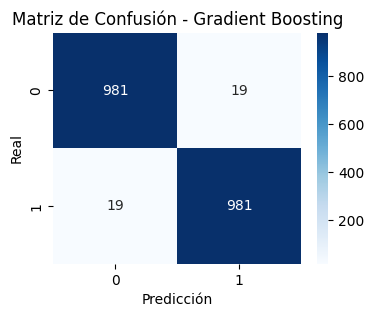

In [109]:
# Accuracy
acc_GB = accuracy_score(y_test_GB, y_pred_GB)
f1_GB = f1_score(y_test_GB, y_pred_GB)
precision_GB = precision_score(y_test_GB, y_pred_GB)
recall_GB = recall_score(y_test_GB, y_pred_GB)
print("Accuracy:", round(acc_GB,4))
print("F1 Score:", round(f1_GB, 4))
print("Precision:", round(precision_GB, 4))
print("Recall:", round(recall_GB, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test_GB, y_pred_GB))

# ROC-AUC
roc_auc = roc_auc_score(y_test_GB, y_prob_gb)
print("\nROC-AUC:", round(roc_auc,4))

# Matriz de confusión
cm_gb = confusion_matrix(y_test_GB, y_pred_GB)

plt.figure(figsize=(4,3))
sns.heatmap(cm_gb, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusión - Gradient Boosting")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

El modelo GB lográ un accuracy del 98.1% en el conjunto de test (predicciones correctas sobre el total de predicciones), con un F1-score equilibrado para ambas clases (aprox 0.98).
La matriz de confusión muestra un número muy reducido de errores (19 falsos positivos y 19 falsos negativos), lo que indica una capacidad de discriminación bastante considerable entre mensajes de odio y no odio. El valor de ROC-AUC (0.997) confirma que el modelo presenta sí separa muy notablemente ambas clases. 

ROC-AUC (Área bajo la curva Receiver Operating Characteristic) mide cuánto se distingue entre clase odio o no odio (1 o 0). Mide la capacidad real de separación entre clases y no se ve tan afectado por el desbalance como el accuracy.

In [110]:
# Se prueba validación cruzada para confirmar estabilidad:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_gb = cross_val_score(
    model_gb,
    X_GB,
    y,
    cv=skf,
    scoring="f1"
)

print("F1 por fold:", scores_gb)
print("F1 medio:", scores_gb.mean())
print("Desviación estándar:", scores_gb.std())

F1 por fold: [0.97695391 0.98198198 0.97897898 0.97693079 0.98156452]
F1 medio: 0.9792820370638289
Desviación estándar: 0.0021697848513538916


Tras aplicar validación cruzada se puede ver que el modelo no solo obtiene un rendimiento muy elevado sino que además es robusto ante distintas particiones de los datos.

## XGBOOST

Accuracy: 0.9815
F1 Score: 0.9815
Precision: 0.981
Recall: 0.982

Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98      1000
         1.0       0.98      0.98      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9973465000000001


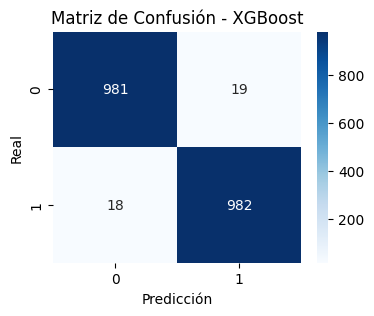

In [111]:
# Métricas
acc_XGB = accuracy_score(y_test_GB, y_pred_xgb)
f1_XGB = f1_score(y_test_GB, y_pred_xgb)
precision_XGB = precision_score(y_test_GB, y_pred_xgb)
recall_XGB = recall_score(y_test_GB, y_pred_xgb)
print("Accuracy:", round(acc_XGB, 4))
print("F1 Score:", round(f1_XGB, 4))
print("Precision:", round(precision_XGB, 4))
print("Recall:", round(recall_XGB, 4))

print("\nClassification Report:")
print(classification_report(y_test_GB, y_pred_xgb))

print("ROC-AUC:", roc_auc_score(y_test_GB, y_prob_xgb))

# Matriz de confusión
cm_xgb = confusion_matrix(y_test_GB, y_pred_xgb)

plt.figure(figsize=(4,3))
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusión - XGBoost")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

Parece que la diferencia con el GB normal es solo 1 falso positivo menos (18 en vez de 19) en el conjunto de test (sin cross validation), por lo que tampoco podríamos decir que la mejora es muy sustancial. Podríamos medir tiempo tiempo de validación cruzada para ver si fuese más rápido aunque se sospecha que la diferencia no séra tan notable ya que el dataset no es tan tan grande. Según la ejecución de las celdas, XGB tarda 0.8 segundos menos (un 80% menos en principio) aunque sería mejor compararlo con datasets mucho más grandes. 

In [112]:
import pickle

## --
# Tamaño de los modelos (se ha usado ChatGPT para obtener esta parte del código)
size_gb = len(pickle.dumps(model_gb))
size_xgb = len(pickle.dumps(model_xgb))

print(f"Tamaño GB:  {size_gb/1024:.1f} KB")
print(f"Tamaño XGB: {size_xgb/1024:.1f} KB")
## --


# Comparamos no. de árboles:

# Gradient Boosting, normalmente = n_estimators
n_trees_gb = model_gb.n_estimators_
print("\nGB - no. árboles:", n_trees_gb)

# XGBoost (boosters = árboles)
booster = model_xgb.get_booster()
n_trees_xgb = booster.num_boosted_rounds()
print("XGB - no. árboles:", n_trees_xgb)

Tamaño GB:  133.9 KB
Tamaño XGB: 277.9 KB

GB - no. árboles: 100
XGB - no. árboles: 200


XGBoost utiliza el doble de árboles que Gradient Boosting y ocupa aproximadamente el doble de tamaño en memoria, lo que refleja una mayor complejidad del modelo y que aunque podría aportar algo más de capacidad predictiva, no siempre se traduce en una mejora notable como puede ser en este caso. Habría que probar ocn otros problemas de clasificación/regresión con datos menos estructurados/preprocesados.  

### TabNet

Accuracy: 0.9765
F1 Score: 0.9768
Precision: 0.9649
Recall: 0.989

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.96      0.98      1000
           1       0.96      0.99      0.98      1000

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9976


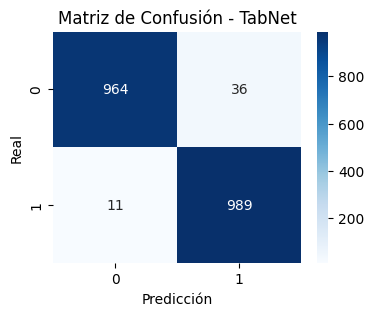

In [113]:
y_pred_TN = model_tabnet.predict(X_test_TN)
y_proba = model_tabnet.predict_proba(X_test_TN)[:, 1]

acc_TN = accuracy_score(y_test_TN, y_pred_TN)
f1_TN = f1_score(y_test_TN, y_pred_TN)
precision_TN = precision_score(y_test_TN, y_pred_TN)
recall_TN = recall_score(y_test_TN, y_pred_TN)

print("Accuracy:", round(acc_TN, 4))
print("F1 Score:", round(f1_TN, 4))
print("Precision:", round(precision_TN, 4))
print("Recall:", round(recall_TN, 4))


print("\nClassification Report:\n", classification_report(y_test_TN, y_pred_TN))
print("ROC-AUC:", round(roc_auc_score(y_test_TN, y_proba), 4))

cm_TN = confusion_matrix(y_test_TN, y_pred_TN)
plt.figure(figsize=(4,3))
sns.heatmap(cm_TN, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusión - TabNet")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

TabNet obtiene un rendimiento bastante elevado con un accuracy del 97.7% y un F1 global de 0.9768, lo que indica equilibrio entre precisión y recall.

El ROC-AUC de 0.9976 confirma una capacidad muy notoria de discriminación entre ambas clases.

A partir de la matriz de confusión se observa que el modelo comete muy pocos errores: solo 36 falsos positivos y 11 falsos negativos, mostrando además una ligera mejor detección de la clase 1 (recall 0.99).

Top 10 features (TabNet):
B          0.200279
B_t        0.181957
E          0.107755
Valor_8    0.063330
Valor_9    0.054909
E_t        0.044442
Valor_1    0.034530
D          0.034530
Valor_7    0.034015
A          0.033528
dtype: float64


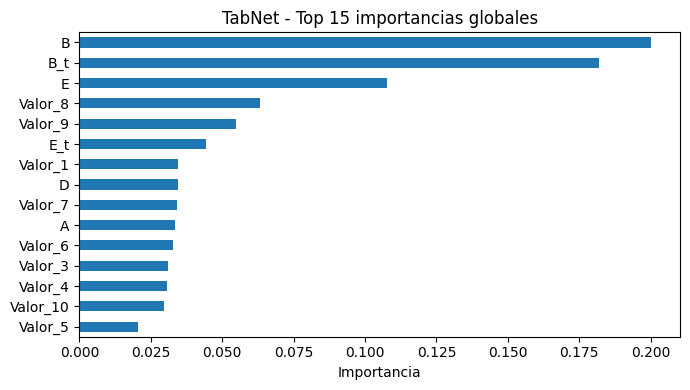

In [114]:
# Importancia de features:

X_TN_Features = df.drop(columns=["label","comentario"]).columns

imp = pd.Series(model_tabnet.feature_importances_, index=X_TN_Features).sort_values(ascending=False)
print("Top 10 features (TabNet):")
print(imp.head(10))

plt.figure(figsize=(7,4))
imp.head(15).sort_values().plot(kind="barh")
plt.title("TabNet - Top 15 importancias globales")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

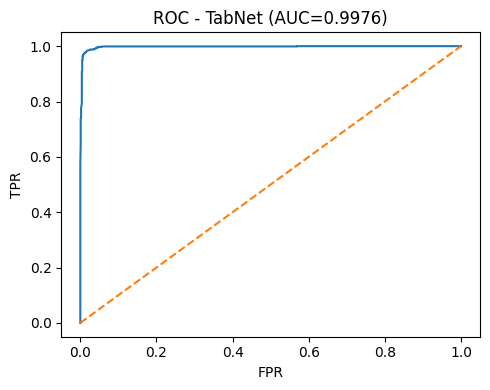

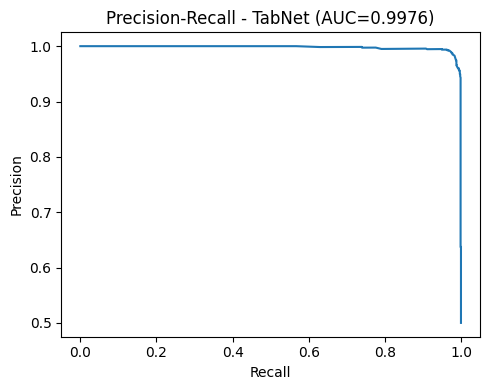

In [115]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc, RocCurveDisplay, PrecisionRecallDisplay

y_prob_TN = model_tabnet.predict_proba(X_test_TN)[:, 1]

# ROC
fpr, tpr, _ = roc_curve(y_test_TN, y_prob_TN)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5,4))
plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle="--")
plt.title(f"ROC - TabNet (AUC={roc_auc:.4f})")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.tight_layout()
plt.show()

# Precision-Recall
prec, rec, _ = precision_recall_curve(y_test_TN, y_prob_TN)
pr_auc = auc(rec, prec)

plt.figure(figsize=(5,4))
plt.plot(rec, prec)
plt.title(f"Precision-Recall - TabNet (AUC={pr_auc:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

La curva ROC queda prácticamente pegada al vértice superior izquierdo y su AUC es de 0.9976, lo que indica que el modelo separa muy bien las dos clases a lo largo de todos los umbrales de decisión.

Además, la curva Precision–Recall también se mantiene muy alta, lo que confirma que el modelo posee una alta precisión incluso cuando se exige “recuperar” la mayor parte de los casos de odio (recall alto).

## CONCLUSIONES

Primero se realizo un análisis exploratorio de datos (EDA) para entender la distribución de las características, la variable objetivo y la relación entre ellas. No requirió limpieza de datos ya que no se encontraron valores nulos o NaNs, y las características numéricas tenían distribuciones razonables.

Después se entrenaron varios modelos de clasificación (Multinomial Naive Bayes, Gradient Boosting, XGBoost y TabNet) utilizando las características del dataset para predecir la variable objetivo "label".

Se evaluaron los modelos utilizando métricas como Accuracy, F1 Score, Precision, Recall, ROC-AUC, además de gráficas, lineas de tendencia o matrices de confusión. 


- Los resulados han sido muy elevados especialmente para Tabnet, lo que sugiere que las características del dataset son muy informativas para la tarea de clasificación. Sin embargo, es importante considerar la posibilidad de sobreajuste, especialmente con modelos más complejos como este último.

- El alto rendimiento se puede deber a que los features no son "crudos", sino que ya han sido procesados y combinados (A–E, A_t–E_t y Valor_1–Valor_10). Esto puede facilitar mucho la tarea de clasificación y que modelos muy simples obtengan resultados elevados, como MultinomialDB. 
- las validaciones cruzadas han demostrado que los resultados son estables, y los modelos de boosting o Tabnet han generado resultados casi óptimos. 

Sobre la elección de los modelos:
- Naive Bayes aporta simplicidad y rapidez, pero asume independencia entre variables.
- Gradient Boosting / XGBoost mejoran notablemente el rendimiento al modelar interacciones no lineales.
- TabNet introduce mecanismos de atención que pueden capturar relaciones complejas entre características, lo que se refleja en su alto rendimiento. Esmás complejo y requiere más recursos computacionales, y para este problema quizá no sea tan necesario. 

Otras métricas que se podrían usar en el futuro: 
- Log Loss (Cross-Entropy): evalúa la calidad probabilística del modelo.
- Brier Score: mide calibración de probabilidades.
- Curva de calibración: evalúa si las probabilidades están bien ajustadas.
- Comparar tiempos de entrenamiento (ya se ha hecho pero no se ha visto mucha diferencia) o curvas de aprendizaje


                                                                                                                       
                                                                                                                       